# 03 - Cleaned Data Visualisation: Healthcare Facilities in Sierra Leone
**Course:** Data Science Fundamentals (FDS)  
**Input Dataset:** `data/cleaned_data.csv` *(1,614 cleaned rows)*  
**Chart Outputs:**  
- `outputs/chart1_facilities_by_district_cleaned.png`  
- `outputs/chart2_facilities_by_type_cleaned.png`  
- `outputs/chart3_facilities_by_ownership_cleaned.png`

---
### Step 1: Load and Verify the Cleaned Dataset
**What this code does:**  
We load `data/cleaned_data.csv` and check its shape, missing values, unique `type` categories, and imputation flag counts (`coords_imputed` and `geo_date_imputed`).

**What the result means:**  
The cleaned dataset has **1,614 rows** (down from 1,616 after removing the 2 confirmed duplicate rows `OID_` 1613 in Tonkolili and `OID_` 1200 in Karene, while keeping the 4 distinct same-name pairs), **16 columns** (the 14 cleaned original columns plus the 2 boolean flag columns `geo_date_imputed` and `coords_imputed`), **0 missing values**, and clean Title Case labels (`'Hospital'` and `'Clinic'`) in the `type` column.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

# Load the cleaned dataset
df_clean = pd.read_csv("data/cleaned_data.csv")

print("Cleaned dataset shape (rows, columns):", df_clean.shape)
print("Total missing values:", int(df_clean.isnull().sum().sum()))
print("Unique facility types:", df_clean["type"].unique().tolist())
print("Facilities with imputed coordinates (coords_imputed == True):", int(df_clean["coords_imputed"].sum()))
print("Facilities with imputed survey year (geo_date_imputed == True):", int(df_clean["geo_date_imputed"].sum()))
df_clean.head()

Cleaned dataset shape (rows, columns): (1614, 16)
Total missing values: 0
Unique facility types: ['MCHP', 'CHP', 'CHC', 'Hospital', 'Clinic']
Facilities with imputed coordinates (coords_imputed == True): 54
Facilities with imputed survey year (geo_date_imputed == True): 54


,OID_,district,community,facility,fac_name,type,ownership,functional,lat,long,source,source_geo,dhis2_id,geo_date,geo_date_imputed,coords_imputed
0,1,Bo,Bum Kaku,Bum Kaku MCHP,Bum Kaku,MCHP,Government,Functional,7.505273,-11.877486,DPPI,GPS,fg1YbsySsK4,2016,False,False
1,2,Bo,Kasse,Kasse MCHP,Kasse,MCHP,Government,Functional,7.536850,-11.919780,DPPI,GPS,d2vcCqeRJJy,2016,False,False
2,3,Bo,Mano Yorgbo,Mano Yorgbo MCHP,Mano Yorgbo,MCHP,Government,Functional,7.558374,-11.869090,DPPI,GPS,shJl21cKmEL,2016,False,False
3,4,Bo,Momajo,Momajo CHP,Momajo,CHP,Government,Functional,7.575193,-11.938020,DPPI,GPS,fRJTlzAV68y,2016,False,False
4,5,Bo,Jimmi,Jimmi CHC,Jimmi,CHC,Government,Functional,7.606090,-11.815840,DPPI,GPS,psVBVk4IYKD,2016,False,False


### Step 2: Chart 1 (Cleaned) — Healthcare Facilities per District in Sierra Leone (`N = 1,614`)
**What this code does:**  
We count the number of healthcare facilities in each district using the cleaned dataset (`1,614` total facilities), plot a horizontal bar chart, and save it as `outputs/chart1_facilities_by_district_cleaned.png`.

**What the result means:**  
The bars now add up to **1,614 unique facilities** (compared to 1,616 in the raw chart):
- **Tonkolili** changed from `113` $ightarrow$ **`112`** (`-1`, after removing the exact duplicate `Ninkikoro MCHP`, `OID_` 1613).  
- **Karene** changed from `63` $ightarrow$ **`62`** (`-1`, after removing the incomplete duplicate `Komoya CHP`, `OID_` 1200).  
- All other 14 districts remain unchanged because same-name facilities with distinct `dhis2_id`s and locations >1 km apart were verified and kept.

Total facilities plotted: 1614
Saved: outputs/chart1_facilities_by_district_cleaned.png


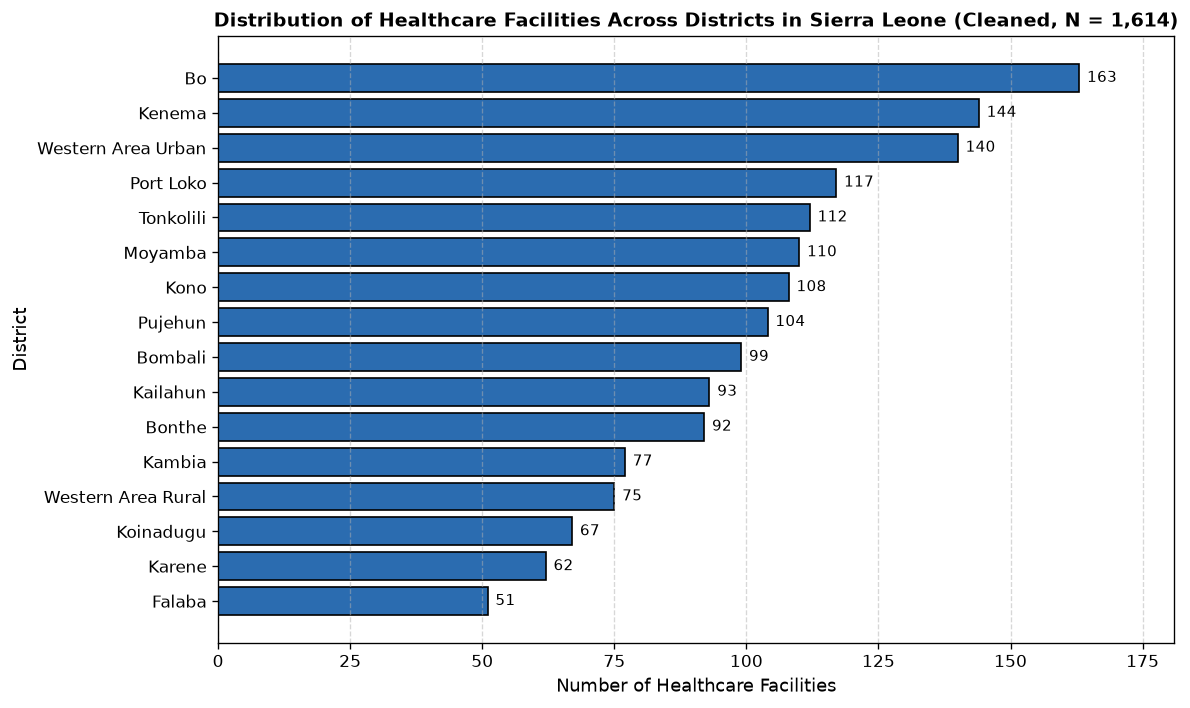

In [2]:
# Chart 1 (Cleaned): Number of Healthcare Facilities by District (N = 1,614)
district_counts_clean = df_clean["district"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.barh(district_counts_clean.index, district_counts_clean.values, color="#2b6cb0", edgecolor="black")
plt.title("Distribution of Healthcare Facilities Across Districts in Sierra Leone (Cleaned, N = 1,614)", fontsize=11.5, fontweight="bold")
plt.xlabel("Number of Healthcare Facilities", fontsize=11)
plt.ylabel("District", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 1.5, bar.get_y() + bar.get_height() / 2, f"{int(width)}", va="center", fontsize=9)

plt.xlim(0, district_counts_clean.max() + 18)
plt.tight_layout()
plt.savefig("outputs/chart1_facilities_by_district_cleaned.png", dpi=150)
plt.show()
print("Total facilities plotted:", int(district_counts_clean.sum()))
print("Saved: outputs/chart1_facilities_by_district_cleaned.png")

### Step 3: Chart 2 (Cleaned) — Healthcare Facilities by Facility Type (`N = 1,614`)
**What this code does:**  
We count the facilities by `type` in the cleaned dataset (`1,614` rows), plot a bar chart showing the standardised Title Case labels (`Hospital` and `Clinic` instead of `HOSPITAL` and `CLINIC`), and save it as `outputs/chart2_facilities_by_type_cleaned.png`.

**What the result means:**  
- **`Hospital`** (`72`) and **`Clinic`** (`128`) are now formatted in clean Title Case (instead of all-caps `HOSPITAL` and `CLINIC`).  
- **`MCHP`** changes from `615` $ightarrow$ **`614`** (after removing duplicate `Ninkikoro MCHP`), and **`CHP`** changes from `486` $ightarrow$ **`485`** (after removing duplicate `Komoya CHP`), while **`CHC`** remains **`315`**, summing to **1,614**.

Total facilities plotted: 1614
Saved: outputs/chart2_facilities_by_type_cleaned.png


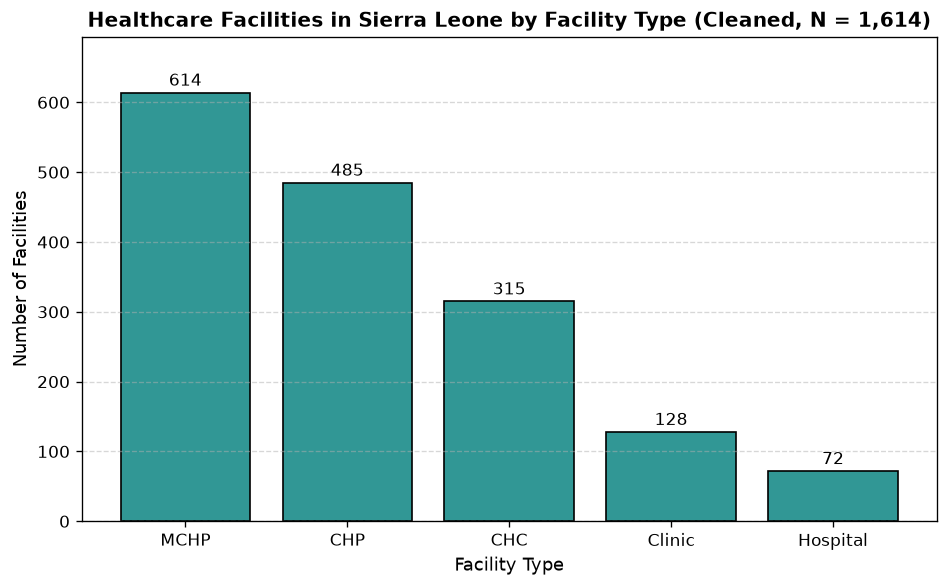

In [3]:
# Chart 2 (Cleaned): Number of Healthcare Facilities by Facility Type (N = 1,614)
type_counts_clean = df_clean["type"].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(type_counts_clean.index, type_counts_clean.values, color="#319795", edgecolor="black")
plt.title("Healthcare Facilities in Sierra Leone by Facility Type (Cleaned, N = 1,614)", fontsize=12, fontweight="bold")
plt.xlabel("Facility Type", fontsize=11)
plt.ylabel("Number of Facilities", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 10, f"{int(height)}", ha="center", fontsize=10)

plt.ylim(0, type_counts_clean.max() + 80)
plt.tight_layout()
plt.savefig("outputs/chart2_facilities_by_type_cleaned.png", dpi=150)
plt.show()
print("Total facilities plotted:", int(type_counts_clean.sum()))
print("Saved: outputs/chart2_facilities_by_type_cleaned.png")

### Step 4: Chart 3 (Cleaned) — Healthcare Facilities by Ownership Category (`N = 1,614`)
**What this code does:**  
We count the facilities by `ownership` in the cleaned dataset (`1,614` rows), plot a bar chart, and save it as `outputs/chart3_facilities_by_ownership_cleaned.png`.

**What the result means:**  
Both duplicate rows removed during cleaning (`Ninkikoro MCHP` and `Komoya CHP`) were Government-owned facilities, so `Government` adjusts from `1,377` to **`1,375`** (`85.19%`), while `Private` (`168`), `Faith Based` (`60`), and `NGO` (`11`) remain unchanged, adding up to **1,614 unique facilities**.

Total facilities plotted: 1614
Saved: outputs/chart3_facilities_by_ownership_cleaned.png


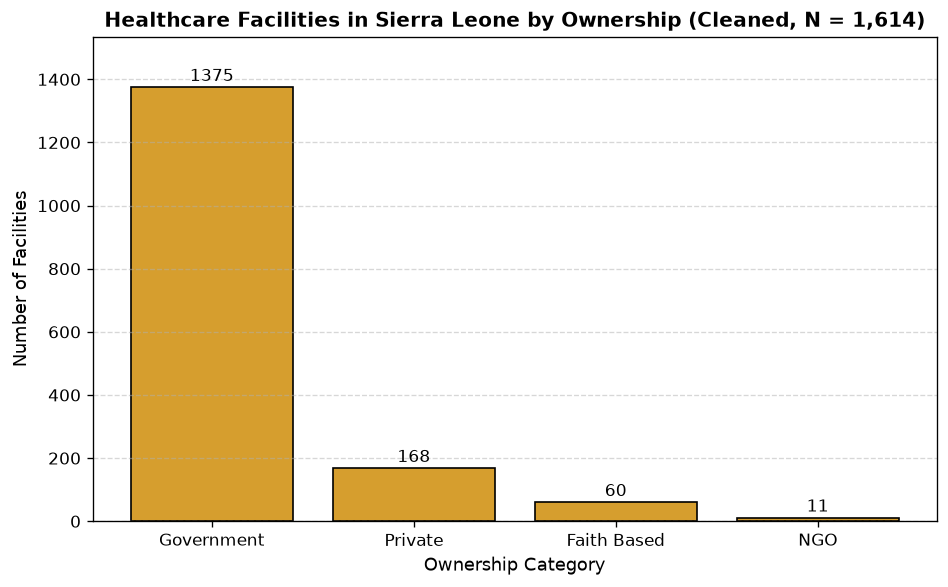

In [4]:
# Chart 3 (Cleaned): Number of Healthcare Facilities by Ownership (N = 1,614)
ownership_counts_clean = df_clean["ownership"].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(ownership_counts_clean.index, ownership_counts_clean.values, color="#d69e2e", edgecolor="black")
plt.title("Healthcare Facilities in Sierra Leone by Ownership (Cleaned, N = 1,614)", fontsize=12, fontweight="bold")
plt.xlabel("Ownership Category", fontsize=11)
plt.ylabel("Number of Facilities", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 20, f"{int(height)}", ha="center", fontsize=10)

plt.ylim(0, ownership_counts_clean.max() + 160)
plt.tight_layout()
plt.savefig("outputs/chart3_facilities_by_ownership_cleaned.png", dpi=150)
plt.show()
print("Total facilities plotted:", int(ownership_counts_clean.sum()))
print("Saved: outputs/chart3_facilities_by_ownership_cleaned.png")